# 22. Кто сдвинулся — камера или пятно?

[План курса](../../README_ru.md)

На двух кадрах оранжевое пятно ползёт вправо. Так бывает, когда оно едет по столу. Тот же сдвиг получится, если стол неподвижен, а камера уезжает влево. Добавим к пятну синюю неподвижную метку и вторую камеру. Теперь у двух объяснений появляются разные следы.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'ru'

## Два затвора

Камеры A и B смотрят вперёд и едут на одной планке. B закреплена на 0.8 м правее A. Оранжевое пятно и синяя метка стоят на глубине 4 м. Ползунок времени передвигает момент съёмки A. Нулевая задержка означает, что B снимает ровно тогда же. Серый прямоугольник при включённой ширме — непрозрачная преграда на полпути к пятну.

In [2]:
display(motion_lab(22, lang))

## Что попадает на один кадр

В нулевой момент пятно находится напротив A. За 0.8 секунды при скорости 1 м/с оно проходит $1\cdot0.8=0.8$ м. Положительное направление — вправо. Если A остаётся на месте, горизонтальное смещение от камеры равно 0.8 м. Глубина $Z=4$ м, поэтому наклон луча $0.8/4=0.2$. Фокус $f=80$ пикселей переводит наклон в $80\cdot0.2=16$ пикселей. Середина кадра $u_0=48$, значит центр пятна окажется в столбце $48+16=64$.

Теперь пятно стоит, зато A движется влево на 0.8 м. Разность положений снова $0-(-0.8)=0.8$ м. У одной оранжевой метки обе истории дали 64 пикселя. Синяя метка закреплена при $X=-1.2$ м. В первой истории она попадает в столбец $48+80(-1.2)/4=24$. Во второй — в $48+80(-1.2+0.8)/4=40$. Появилась деталь, по которой различаются два движения.

Запишем оба случая вместе. $X(t)$ — положение пятна, $C(t)$ — положение камеры по горизонтали в метрах в момент $t$ секунд. При постоянной положительной глубине длины в дроби сокращаются. Результат $u(t)$ измеряется в пикселях.

$$
u(t)=u_0+f\frac{X(t)-C(t)}{Z}.
$$

In [3]:
for object_speed, camera_speed in [(1, 0), (0, -1), (1, 1)]:
    left = motion.observing_pair(.8, object_speed, camera_speed)[0][0]
    print(f"v = {object_speed:+d}, camera = {camera_speed:+d} m/s   orange = {left['u']:.1f}, blue = {left['anchor']:.1f} px")

v = +1, camera = +0 m/s   orange = 64.0, blue = 24.0 px
v = +0, camera = -1 m/s   orange = 64.0, blue = 40.0 px
v = +1, camera = +1 m/s   orange = 48.0, blue = 8.0 px


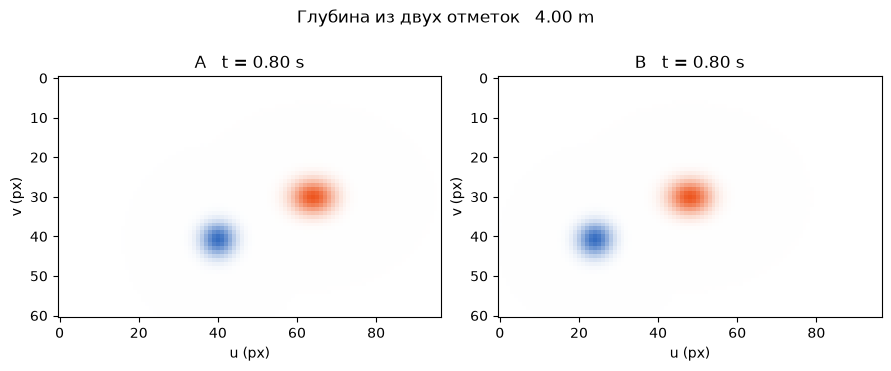

In [4]:
fig = motion_figure(22, lang, time=.8, object_speed=0, camera_speed=-1)
plt.show()

## Откуда взялась неверная глубина

При неподвижной планке A снимает пятно в столбце 64. В тот же момент B стоит при $C_B=0.8$ м, прямо напротив пятна, поэтому $u_B=48$. Разность $d=u_A-u_B=16$ пикселей называется диспаратностью. Если вычесть две проекции **одного положения** пятна, его координата $X$ сократится. Останется расстояние между камерами $b=C_B-C_A$. Для положительного $d$ получаем

$$
\begin{aligned}
d&=\frac{f}{Z}\big((X-C_A)-(X-C_B)\big)=\frac{fb}{Z},\\
Z&=\frac{fb}{d}=\frac{80\cdot0.8}{16}=4\ \mathrm{m}.
\end{aligned}
$$

Теперь B опоздала на 0.2 секунды. Пятно успело сдвинуться до $X=1$ м. Камера B видит $48+80(1-0.8)/4=52$. Формула для синхронной пары выдаст $64/(64-52)=5.33$ м. Входные пиксели верны, но их лучи вышли к пятну в разные моменты. Если задержка достигнет 0.8 с, разность обнулится. Деление на ноль глубины не даёт.

In [5]:
for lag in [0, .2, .8]:
    views, disparity, z = motion.observing_pair(lag=lag)
    print('Δt', lag, 's   u', [round(v['u'], 2) for v in views], 'px   d', round(disparity, 2), 'px   Z', z)

Δt 0 s   u [64.0, 48.0] px   d 16.0 px   Z 4.0
Δt 0.2 s   u [64.0, 52.0] px   d 12.0 px   Z 5.333333333333333
Δt 0.8 s   u [64.0, 64.0] px   d 0.0 px   Z None


## Чего нет между кадрами

У ширмы глубина 2 м, у пятна 4 м. На полпути горизонтальная координата луча равна среднему двух концов. Для A это $(0+0.8)/2=0.4$ м, внутри полосы от 0.28 до 0.52 м. Для B получится $(0.8+0.8)/2=0.8$ м, за краем полосы. В правом кадре центр ещё виден, в левом он закрыт. Даже если у края остался рыжий хвост гауссианы, положения закрытого центра он сам по себе не сообщает.

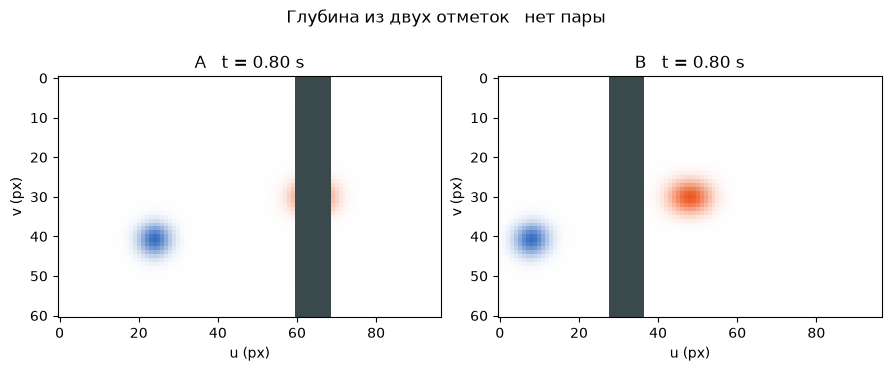

In [6]:
fig = motion_figure(22, lang, gate=True)
plt.show()

**Что останется неизвестным?** Две синхронные камеры восстановили центр в моменты 0 и 2 с. Достаточно ли этого, чтобы узнать положение через секунду?

<details><summary>Разбор</summary>

В каждом из снятых моментов пара ограничивает глубину. Между ними наблюдений нет. Пятно могло ехать равномерно, замедлиться или отклониться в сторону и успеть вернуться. Прямая между двумя центрами добавляет предположение о движении. Эксперимент со следующим пятном покажет цену этого предположения в пикселях.

</details>